In [120]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json

In [121]:
data = pd.read_csv("données/LucasBenjamin_5ae9cde00335e200019e9eed.csv", skiprows=1, index_col=3)
data

,rt,url,trial_type,time_elapsed,internal_node_id,success,responses,view_history,trial_rt,response_rts,stimulus,presented_angles,stimulus_rotations,key_press,final_angle,confidence,target,score,correct
trial_index,,,,,,,,,,,,,,,,,,,
0,18657.0,external-consent.html,external-html,18692,0.0-0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,fullscreen,23307,0.0-1.0,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,14396.0,NaN,survey-dropdown,37704,0.0-2.0,NaN,"{""0"":""25-40"",""1"":""F""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,69634.0,NaN,survey-text,107340,0.0-3.0,NaN,"{""Q0"":""5ae9cde00335e200019e9eed""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,80368.0,NaN,instructions,187708,0.0-4.0,NaN,NaN,"[{""page_index"":0,""viewing_time"":48649},{""page_...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,NaN,NaN,lb-SeqAns-visual,4828326,0.0-224.0,NaN,NaN,NaN,2426.0,NaN,Stims/Gabor_img/Gabor_0.png,218.4099821053,-45,NaN,-9.130176,0.0,173.409982,10.0,NaN
284,NaN,NaN,lb-SeqAns-visual,4833865,0.0-225.0,NaN,NaN,NaN,2508.0,NaN,Stims/Gabor_img/Gabor_0.png,195.9147529961,0,NaN,15.718573,0.0,15.914753,10.0,NaN
285,NaN,NaN,lb-SeqAns-visual,4844768,0.0-226.0,NaN,NaN,NaN,1822.0,NaN,Stims/Gabor_img/Gabor_0.png,"159.3437590786,153.8696178772,90.66764952,150....","-45,-45,0,0,0",NaN,-79.343152,0.0,105.643527,10.0,NaN


## Fonctions

In [122]:
def CircularMean(a):
    if len(a)==0:
        return(np.nan)
    resulting_vector = 0
    for i in range(len(a)):
        if not  np.isnan(a[i]):
            resulting_vector+= cmath.exp(complex(0, a[i]))
    return(np.angle(resulting_vector))

In [123]:
def Angle_moyen_circulaire(angle_list_rad):
    rad_doubled = 2 * angle_list_rad                         # ×2 AVANT
    mean_doubled = CircularMean(rad_doubled)                 # TA fonction (rad)
    mean_ori_rad = mean_doubled / 2                          # ÷2 APRÈS
    return mean_ori_rad                               

In [124]:
def circular_error(a, b):
    return ((a - b + np.pi/2) % np.pi) - np.pi/2   # équivalent de [-90°, +90°]

def circular_error_deg(a, b):
    return ((a - b + 180/2) % 180) - 180/2   # équivalent de [-90°, +90°]

In [125]:
# norme du vecteur moyen circulaire pour des orientations. Retourne une valeur entre 0 et 1
# Proche de 1 = angles très proches, proche de 0 = angles très dispersés

def confiance (angle_list_rad) :
    if len(angle_list_rad)==0:
        return(np.nan)
    doubled = 2*angle_list_rad
    resultant = 0 
    for theta in doubled:
        if not np.isnan(theta):
            resultant += cmath.exp(complex(0, theta))
    return abs(resultant) / len(angle_list_rad)

## Filtering du dataframe pour 1 sujet

### dataframe en degré

In [126]:
df_filtered = data[data["stimulus_rotations"].notna()]
df_filtered = df_filtered.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered["length of sequence"] = df_filtered["presented_angles"].apply(lambda s: len(s.split(',')) if isinstance(s, str) else 0)
df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['score'] = df_filtered['score'].astype(int)
df_filtered["expected_angles"] = df_filtered.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)
df_filtered["expected_targets"] = df_filtered['expected_angles'].apply(np.mean)%180 # the best they could have done with what they were given


df_filtered = df_filtered.dropna(subset=["final_angle"])

### dataframe en radian

In [160]:
df_radian = df_filtered.copy().drop(columns=["presented_angles", "final_angle", "target", "expected_angles", "expected_targets", "stimulus_rotations"])
df_radian['final_angle'] = np.deg2rad(df_filtered['final_angle'])

df_radian['target'] = np.deg2rad(df_filtered['target'])
df_radian['expected_targets'] = np.deg2rad(df_filtered['expected_targets'])

df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian["rad_target_expected"] = df_radian["expected_angles"].apply(Angle_moyen_circulaire) # moyenne circulaire des angles attendus  

df_radian

,trial_rt,score,length of sequence,error_to_target,mean_rotation,final_angle,target,expected_targets,stimulus_rotations,presented_angles,expected_angles,rad_target_expected
0,2305.0,6,3,12.188493,-15.000000,-0.430167,2.498241,2.498696,"[-0.7853981633974483, -0.7853981633974483, 0.7...","[3.252067471445352, 3.0106727580067814, 2.0187...","[2.466669308047903, 2.225274594609333, 2.80414...",-0.644843
1,1958.0,0,7,33.928460,-12.857143,-0.243618,2.315405,2.305811,"[0.7853981633974483, -0.7853981633974483, 0.78...","[1.7115227546124807, 3.371987102063714, 0.8661...","[2.496920918009929, 2.586588938666266, 1.65156...",-0.789767
2,2380.0,6,5,16.572541,18.000000,2.554998,2.278856,2.265753,"[0.7853981633974483, 0.7853981633974483, 0.0, ...","[0.5934584351721087, 1.3713946414614882, 2.517...","[1.378856598569557, 2.156792804858936, 2.51714...",-0.808343
3,1969.0,0,3,-44.540986,-30.000000,0.921122,1.697874,1.698509,"[0.0, -0.7853981633974483, -0.7853981633974483]","[1.5153946746771307, 2.405401029975197, 2.7455...","[1.5153946746771307, 1.6200028665777488, 1.960...",-1.445733
4,1735.0,10,7,-1.902656,-12.857143,3.651889,0.544458,0.543504,"[-0.7853981633974483, -0.7853981633974483, 0.7...","[1.731041275770652, 1.5914395297000938, -0.393...","[0.9456431123732036, 0.8060413663026454, 0.392...",0.547585
...,...,...,...,...,...,...,...,...,...,...,...,...
195,2426.0,10,1,-2.540159,-45.000000,-0.159352,3.026575,3.026575,[-0.7853981633974483],[3.8119733069593815],[3.0265751435619332],-0.115018
196,2508.0,10,1,-0.196180,0.000000,0.274341,0.277765,0.277765,[0.0],[3.4193574930133703],[3.4193574930133703],0.277765
197,1822.0,10,5,-5.166511,-18.000000,-1.384799,1.843827,1.846966,"[-0.7853981633974483, -0.7853981633974483, 0.0...","[2.781073238426176, 2.6855314507426677, 1.5824...","[1.9956750750287275, 1.9001332873452197, 1.582...",-1.310359
198,1814.0,0,1,-89.342757,-45.000000,-1.035841,0.523484,0.523484,[-0.7853981633974483],[1.3088821824978711],[0.5234840191004229],0.523484


## exploration métadatas

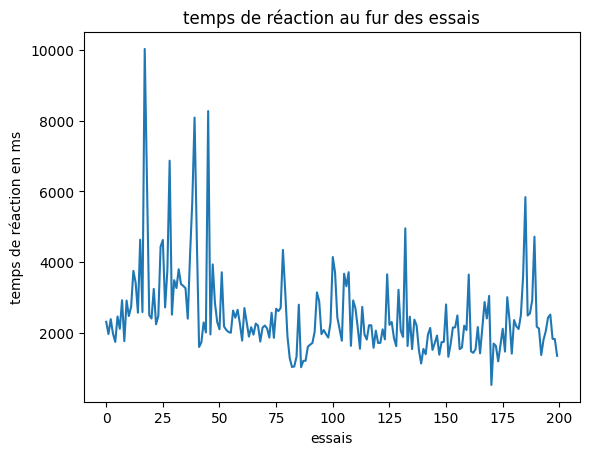

In [161]:
plt.plot(df_filtered["trial_rt"])
plt.title("temps de réaction au fur des essais")
plt.xlabel("essais")
plt.ylabel("temps de réaction en ms")
plt.show()

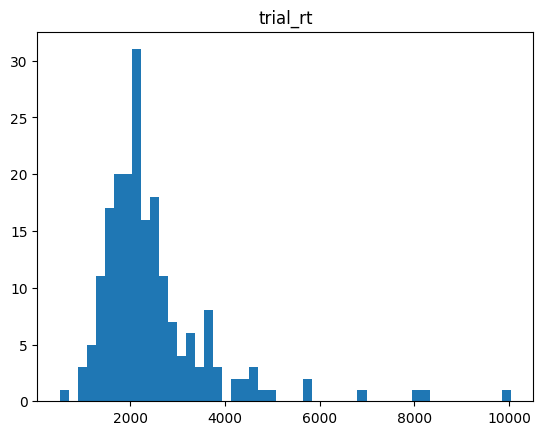

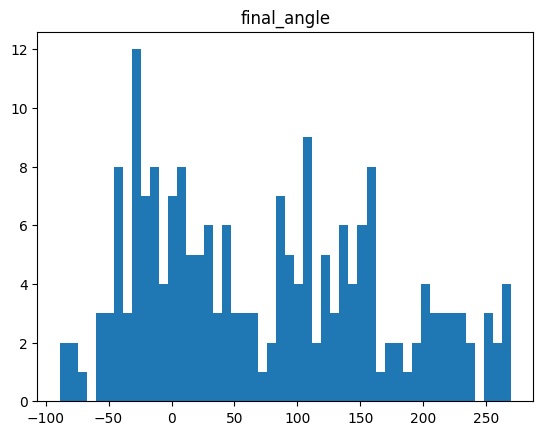

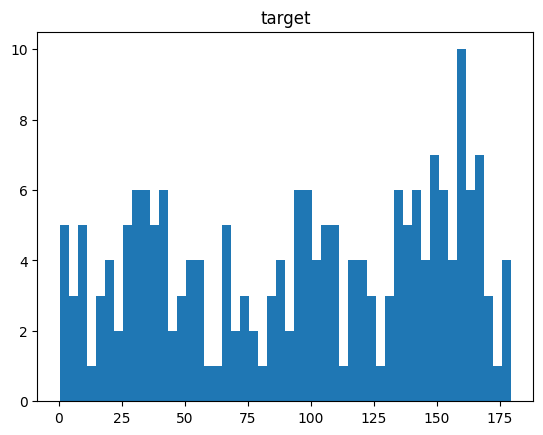

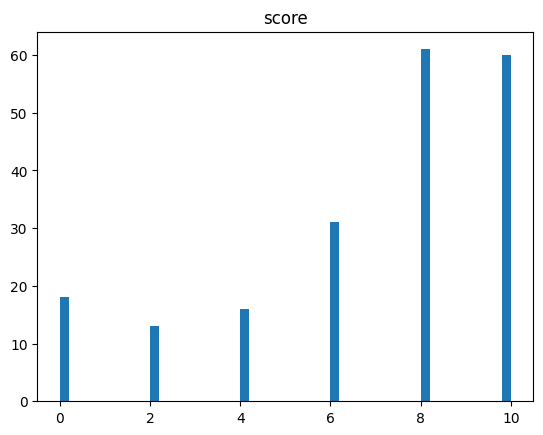

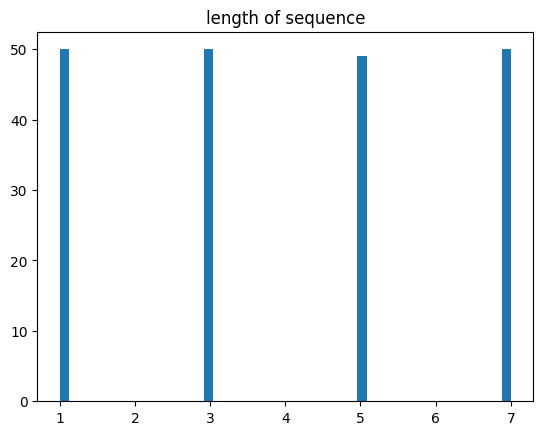

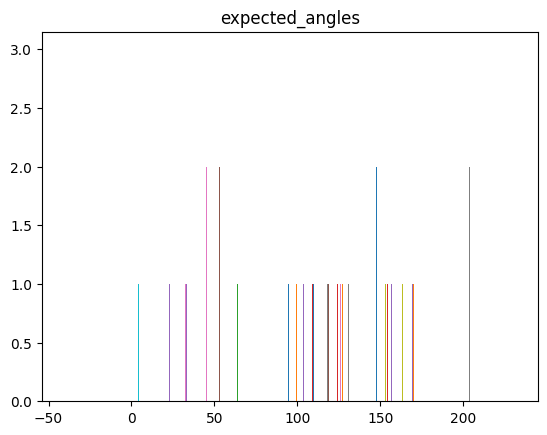

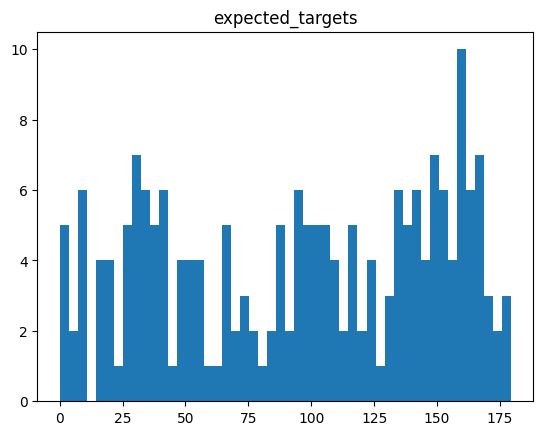

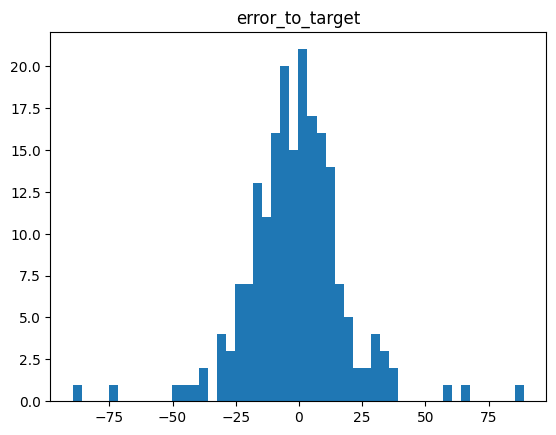

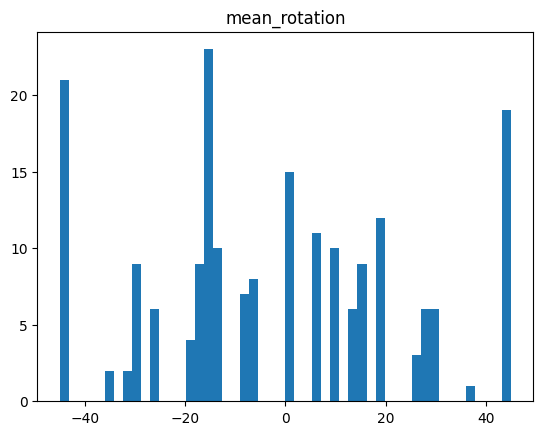

In [162]:
for column in df_filtered.columns:
    if column not in ["presented_angles", "stimulus_rotations"]:
        plt.figure()
        plt.hist(df_filtered[column], bins=50)
        plt.title(column)
        plt.show()

### data sur tous les participants

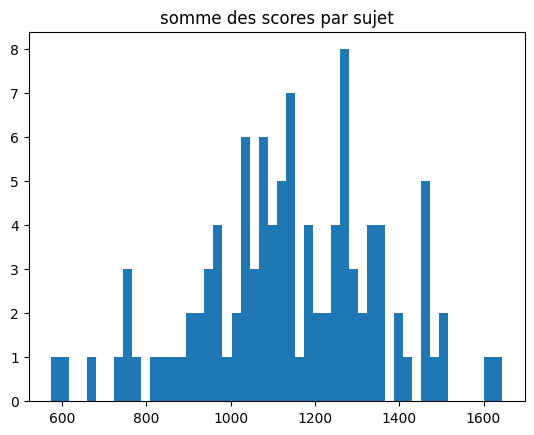

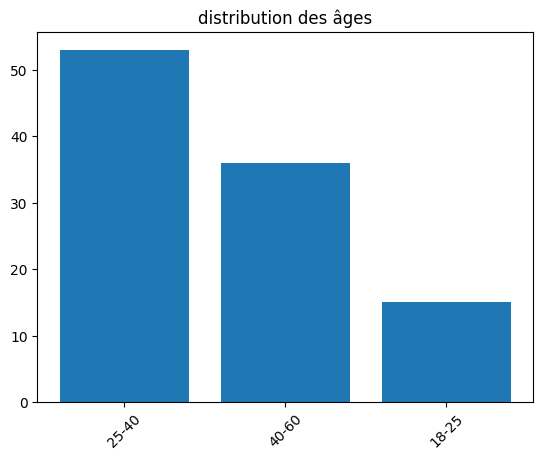

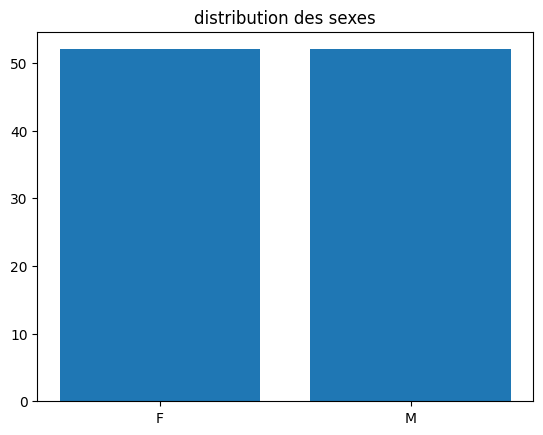

In [163]:
filepaths = glob.glob("données/*.csv")
dfs = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepaths]

def data_sujets (dfs) : 
    score_sum = []
    age_tot = []
    sexe_tot = []
    for df in dfs :    
        survey = df[df["trial_type"] == "survey-dropdown"]
        if len(survey) == 0:
            age, sexe = None, None
        else:
            resp = json.loads(survey.iloc[0]["responses"])
            age = resp.get("0")
            sexe = resp.get("1")        
        age_tot.append(age)
        sexe_tot.append(sexe)
        
        df_filtered = df[df["stimulus_rotations"].notna()].copy()
        df_filtered = df_filtered.dropna(subset=["final_angle"]).copy()
        
        df_filtered['score'] = pd.to_numeric(df_filtered["score"], errors="coerce")
        score_sum.append(df_filtered["score"].sum(skipna=True))
        
    return score_sum, age_tot, sexe_tot

scores, ages, sexes = data_sujets(dfs)

plt.hist(scores, bins=50)
plt.title("somme des scores par sujet")
plt.show()

age_counts = pd.Series(ages).value_counts(dropna=False)
plt.bar(age_counts.index.astype(str), age_counts.values)
plt.xticks(rotation=45)
plt.title("distribution des âges")
plt.show()

sex_counts = pd.Series(sexes).value_counts(dropna=False)
plt.bar(sex_counts.index.astype(str), sex_counts.values)
plt.title("distribution des sexes")
plt.show()

In [164]:
print("il y a",sexes.count('F'), "femmes"), print("il y a",sexes.count('M'), 'hommes'), print("il y a",ages.count('18-25'), "personnes qui ont entre 18 et 25 ans"),
print("il y a",ages.count('25-40'), 'personnes qui ont entre 25 et 40 ans'), print("il y a",ages.count('40-60'), 'personnes qui ont entre 40 et 60 ans')

il y a 52 femmes
il y a 52 hommes
il y a 15 personnes qui ont entre 18 et 25 ans
il y a 53 personnes qui ont entre 25 et 40 ans
il y a 36 personnes qui ont entre 40 et 60 ans


(None, None)

### Disposition des angles sur un cercle

ici je dois changer en mettant le cercle de -90° à 90°
ca c'est bizarre


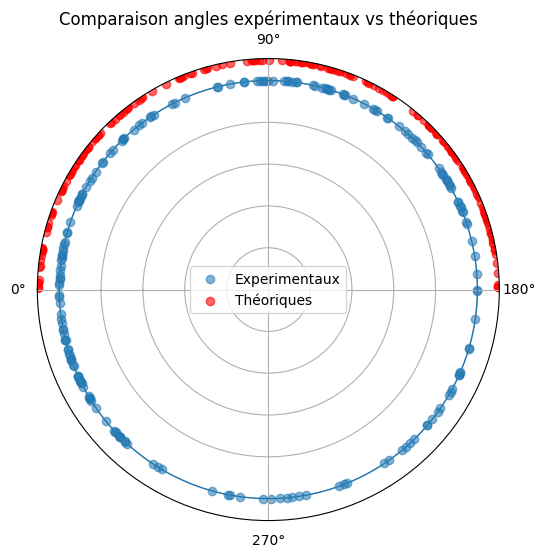

In [165]:
fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

ax.set_theta_zero_location("W")   # 0° à gauche (comme ton choix)
ax.set_theta_direction(-1)        # sens horaire

# ---- CERCLE TRIGONOMÉTRIQUE ----
theta = np.linspace(0, 2*np.pi, 400)
ax.plot(theta, np.ones_like(theta), linewidth=1)  # cercle unité

# labels angulaires
ax.set_thetagrids(
    angles=[0, 90, 180, 270],
    labels=["0°", "90°", "180°", "270°"]
)

# ---- TES DONNÉES ----
theta_presented = df_radian['final_angle'].values
theta_targets = df_radian['target'].values

ax.scatter(theta_presented, np.ones_like(theta_presented),
           alpha=0.55, label="Experimentaux")

ax.scatter(theta_targets, np.ones_like(theta_targets)*1.1,
           color='red', alpha=0.6, label="Théoriques")

ax.set_yticklabels([])   # enlève les labels du rayon
ax.set_title("Comparaison angles expérimentaux vs théoriques")
ax.legend()

plt.show()

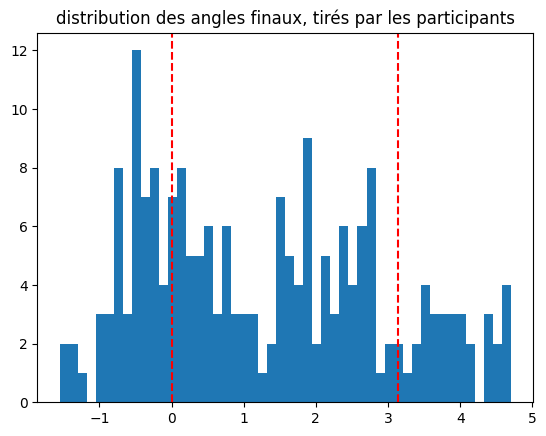

In [166]:
plt.hist(df_radian["final_angle"], bins=50)
plt.axvline(0, color='red', linestyle='--')
plt.axvline(np.pi, color='red', linestyle='--')
plt.title("distribution des angles finaux, tirés par les participants")
plt.show()

## Performances

### Est ce que les participants ont bien répondu ? (erreur entre angle tiré et la target) 

+ ajouter la confiance pour voir la distribution de la confiance pour les angles expected 

In [167]:
df_radian["error_to_target"] = circular_error(df_radian["final_angle"], df_radian["expected_targets"]) # erreur par rapport à l'angle théorique
df_filtered["error_to_target"] = circular_error_deg(df_filtered["final_angle"], df_filtered["expected_targets"]) # erreur par rapport à l'angle théorique

In [168]:
df_radian

,trial_rt,score,length of sequence,error_to_target,mean_rotation,final_angle,target,expected_targets,stimulus_rotations,presented_angles,expected_angles,rad_target_expected
0,2305.0,6,3,0.212729,-15.000000,-0.430167,2.498241,2.498696,"[-0.7853981633974483, -0.7853981633974483, 0.7...","[3.252067471445352, 3.0106727580067814, 2.0187...","[2.466669308047903, 2.225274594609333, 2.80414...",-0.644843
1,1958.0,0,7,0.592163,-12.857143,-0.243618,2.315405,2.305811,"[0.7853981633974483, -0.7853981633974483, 0.78...","[1.7115227546124807, 3.371987102063714, 0.8661...","[2.496920918009929, 2.586588938666266, 1.65156...",-0.789767
2,2380.0,6,5,0.289245,18.000000,2.554998,2.278856,2.265753,"[0.7853981633974483, 0.7853981633974483, 0.0, ...","[0.5934584351721087, 1.3713946414614882, 2.517...","[1.378856598569557, 2.156792804858936, 2.51714...",-0.808343
3,1969.0,0,3,-0.777387,-30.000000,0.921122,1.697874,1.698509,"[0.0, -0.7853981633974483, -0.7853981633974483]","[1.5153946746771307, 2.405401029975197, 2.7455...","[1.5153946746771307, 1.6200028665777488, 1.960...",-1.445733
4,1735.0,10,7,-0.033208,-12.857143,3.651889,0.544458,0.543504,"[-0.7853981633974483, -0.7853981633974483, 0.7...","[1.731041275770652, 1.5914395297000938, -0.393...","[0.9456431123732036, 0.8060413663026454, 0.392...",0.547585
...,...,...,...,...,...,...,...,...,...,...,...,...
195,2426.0,10,1,-0.044334,-45.000000,-0.159352,3.026575,3.026575,[-0.7853981633974483],[3.8119733069593815],[3.0265751435619332],-0.115018
196,2508.0,10,1,-0.003424,0.000000,0.274341,0.277765,0.277765,[0.0],[3.4193574930133703],[3.4193574930133703],0.277765
197,1822.0,10,5,-0.090173,-18.000000,-1.384799,1.843827,1.846966,"[-0.7853981633974483, -0.7853981633974483, 0.0...","[2.781073238426176, 2.6855314507426677, 1.5824...","[1.9956750750287275, 1.9001332873452197, 1.582...",-1.310359
198,1814.0,0,1,-1.559325,-45.000000,-1.035841,0.523484,0.523484,[-0.7853981633974483],[1.3088821824978711],[0.5234840191004229],0.523484


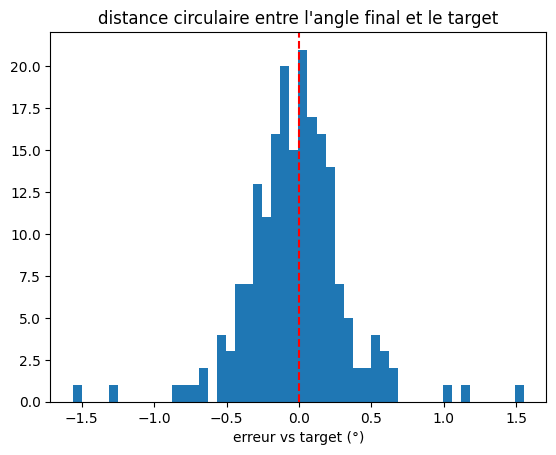

In [169]:
plt.hist(df_radian["error_to_target"], bins=50)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("erreur vs target (°)")
plt.title("distance circulaire entre l'angle final et le target")
plt.show()

### Est ce que les participants ignorent les rotations ? (ne considèrent que les gris)

j'ai besoin de prendre toutes les presented angles, et de garder seulement les 0°, et de comparer leur moyenne circulaire avec l'angle final tiré


In [170]:
df_radian["dict_angle_to_rotation"]= df_radian.apply(lambda row: dict(zip(row["presented_angles"], row["stimulus_rotations"])), axis=1) 
df_radian

,trial_rt,score,length of sequence,error_to_target,mean_rotation,final_angle,target,expected_targets,stimulus_rotations,presented_angles,expected_angles,rad_target_expected,dict_angle_to_rotation
0,2305.0,6,3,0.212729,-15.000000,-0.430167,2.498241,2.498696,"[-0.7853981633974483, -0.7853981633974483, 0.7...","[3.252067471445352, 3.0106727580067814, 2.0187...","[2.466669308047903, 2.225274594609333, 2.80414...",-0.644843,"{3.252067471445352: -0.7853981633974483, 3.010..."
1,1958.0,0,7,0.592163,-12.857143,-0.243618,2.315405,2.305811,"[0.7853981633974483, -0.7853981633974483, 0.78...","[1.7115227546124807, 3.371987102063714, 0.8661...","[2.496920918009929, 2.586588938666266, 1.65156...",-0.789767,"{1.7115227546124807: 0.7853981633974483, 3.371..."
2,2380.0,6,5,0.289245,18.000000,2.554998,2.278856,2.265753,"[0.7853981633974483, 0.7853981633974483, 0.0, ...","[0.5934584351721087, 1.3713946414614882, 2.517...","[1.378856598569557, 2.156792804858936, 2.51714...",-0.808343,"{0.5934584351721087: 0.7853981633974483, 1.371..."
3,1969.0,0,3,-0.777387,-30.000000,0.921122,1.697874,1.698509,"[0.0, -0.7853981633974483, -0.7853981633974483]","[1.5153946746771307, 2.405401029975197, 2.7455...","[1.5153946746771307, 1.6200028665777488, 1.960...",-1.445733,"{1.5153946746771307: 0.0, 2.405401029975197: -..."
4,1735.0,10,7,-0.033208,-12.857143,3.651889,0.544458,0.543504,"[-0.7853981633974483, -0.7853981633974483, 0.7...","[1.731041275770652, 1.5914395297000938, -0.393...","[0.9456431123732036, 0.8060413663026454, 0.392...",0.547585,"{1.731041275770652: -0.7853981633974483, 1.591..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,2426.0,10,1,-0.044334,-45.000000,-0.159352,3.026575,3.026575,[-0.7853981633974483],[3.8119733069593815],[3.0265751435619332],-0.115018,{3.8119733069593815: -0.7853981633974483}
196,2508.0,10,1,-0.003424,0.000000,0.274341,0.277765,0.277765,[0.0],[3.4193574930133703],[3.4193574930133703],0.277765,{3.4193574930133703: 0.0}
197,1822.0,10,5,-0.090173,-18.000000,-1.384799,1.843827,1.846966,"[-0.7853981633974483, -0.7853981633974483, 0.0...","[2.781073238426176, 2.6855314507426677, 1.5824...","[1.9956750750287275, 1.9001332873452197, 1.582...",-1.310359,"{2.781073238426176: -0.7853981633974483, 2.685..."
198,1814.0,0,1,-1.559325,-45.000000,-1.035841,0.523484,0.523484,[-0.7853981633974483],[1.3088821824978711],[0.5234840191004229],0.523484,{1.3088821824978711: -0.7853981633974483}


In [171]:
df_radian["angles_sans_rotation"]= df_radian["dict_angle_to_rotation"].apply(lambda d: [angle for angle, rot in d.items() if np.isclose(rot, 0)])

df_radian_error_wo_rotation = df_radian[df_radian["angles_sans_rotation"].apply(len)>0]

df_radian_error_wo_rotation["error_sola_gris"] = circular_error(df_radian_error_wo_rotation["final_angle"], df_radian_error_wo_rotation["angles_sans_rotation"].apply(Angle_moyen_circulaire))
df_radian_error_wo_rotation

/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_25558/2690521830.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_radian_error_wo_rotation["error_sola_gris"] = circular_error(df_radian_error_wo_rotation["final_angle"], df_radian_error_wo_rotation["angles_sans_rotation"].apply(Angle_moyen_circulaire))


,trial_rt,score,length of sequence,error_to_target,mean_rotation,final_angle,target,expected_targets,stimulus_rotations,presented_angles,expected_angles,rad_target_expected,dict_angle_to_rotation,angles_sans_rotation,error_sola_gris
1,1958.0,0,7,0.592163,-12.857143,-0.243618,2.315405,2.305811,"[0.7853981633974483, -0.7853981633974483, 0.78...","[1.7115227546124807, 3.371987102063714, 0.8661...","[2.496920918009929, 2.586588938666266, 1.65156...",-0.789767,"{1.7115227546124807: 0.7853981633974483, 3.371...",[2.6411345845106764],-1.564185
2,2380.0,6,5,0.289245,18.000000,2.554998,2.278856,2.265753,"[0.7853981633974483, 0.7853981633974483, 0.0, ...","[0.5934584351721087, 1.3713946414614882, 2.517...","[1.378856598569557, 2.156792804858936, 2.51714...",-0.808343,"{0.5934584351721087: 0.7853981633974483, 1.371...","[2.517148657266629, 2.326270515163634, 2.94969...",1.256804
3,1969.0,0,3,-0.777387,-30.000000,0.921122,1.697874,1.698509,"[0.0, -0.7853981633974483, -0.7853981633974483]","[1.5153946746771307, 2.405401029975197, 2.7455...","[1.5153946746771307, 1.6200028665777488, 1.960...",-1.445733,"{1.5153946746771307: 0.0, 2.405401029975197: -...",[1.5153946746771307],0.163425
4,1735.0,10,7,-0.033208,-12.857143,3.651889,0.544458,0.543504,"[-0.7853981633974483, -0.7853981633974483, 0.7...","[1.731041275770652, 1.5914395297000938, -0.393...","[0.9456431123732036, 0.8060413663026454, 0.392...",0.547585,"{1.731041275770652: -0.7853981633974483, 1.591...",[0.061922982618465],0.479335
5,2455.0,6,3,-0.255892,-30.000000,1.321900,1.575600,1.577791,"[-0.7853981633974483, 0.0, -0.7853981633974483]","[2.072752520458921, 1.4682404373779747, 2.7631...","[1.2873543570614727, 1.4682404373779747, 1.977...",1.568073,"{2.072752520458921: -0.7853981633974483, 1.468...",[1.4682404373779747],0.587780
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191,2112.0,8,7,0.186734,19.285714,2.280391,2.091023,2.093657,"[0.0, 0.7853981633974483, 0.7853981633974483, ...","[2.1480479074728103, 1.2040212780009145, 1.196...","[2.1480479074728103, 1.9894194413983628, 1.982...",-1.059594,"{2.1480479074728103: 0.0, 1.2040212780009145: ...","[2.1480479074728103, 1.8242175696786707]",1.287324
192,1363.0,6,5,-0.305198,9.000000,1.832916,2.138109,2.138114,"[0.0, 0.7853981633974483, -0.7853981633974483,...","[2.114254049035857, 1.3160260339870815, 2.9882...","[2.114254049035857, 2.10142419738453, 2.202883...",-1.003498,"{2.114254049035857: 0.0, 1.3160260339870815: 0...","[2.114254049035857, 2.066152983709209]",0.787814
194,2039.0,10,3,-0.012371,30.000000,1.937246,1.949679,1.949617,"[0.0, 0.7853981633974483, 0.7853981633974483]","[1.9574160555280071, 0.9426292138039282, 1.378...","[1.9574160555280071, 1.7280273772013763, 2.163...",-1.191717,"{1.9574160555280071: 0.0, 0.9426292138039282: ...",[1.9574160555280071],0.958537
196,2508.0,10,1,-0.003424,0.000000,0.274341,0.277765,0.277765,[0.0],[3.4193574930133703],[3.4193574930133703],0.277765,{3.4193574930133703: 0.0},[3.4193574930133703],-1.435338


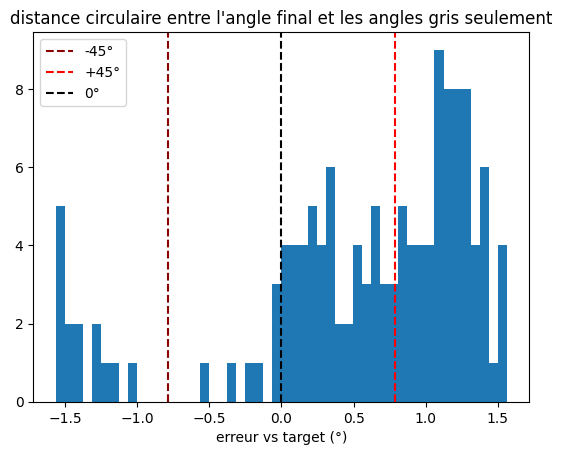

In [172]:
plt.hist(df_radian_error_wo_rotation["error_sola_gris"], bins=50)
plt.axvline(np.deg2rad(-45), color='darkred', linestyle='--', label="-45°") 
plt.axvline(np.deg2rad(45), color='red', linestyle='--', label="+45°") 
plt.axvline(np.deg2rad(0), color='black', linestyle='--', label="0°") 

plt.xlabel("erreur vs target (°)")
plt.title("distance circulaire entre l'angle final et les angles gris seulement")
plt.legend()
plt.show()

### Est ce que les participants ignorent les rotations ? (ne prennent pas en compte les couleurs, seulement les orientations qu'ils voient)

In [173]:
df_radian["expected_angles_wo_rot"] = df_radian["presented_angles"].apply(Angle_moyen_circulaire)
df_radian["error_wo_rotation"] = circular_error(df_radian["final_angle"], df_radian["expected_angles_wo_rot"])  
df_radian

,trial_rt,score,length of sequence,error_to_target,mean_rotation,final_angle,target,expected_targets,stimulus_rotations,presented_angles,expected_angles,rad_target_expected,dict_angle_to_rotation,angles_sans_rotation,expected_angles_wo_rot,error_wo_rotation
0,2305.0,6,3,0.212729,-15.000000,-0.430167,2.498241,2.498696,"[-0.7853981633974483, -0.7853981633974483, 0.7...","[3.252067471445352, 3.0106727580067814, 2.0187...","[2.466669308047903, 2.225274594609333, 2.80414...",-0.644843,"{3.252067471445352: -0.7853981633974483, 3.010...",[],-0.278611,-0.151556
1,1958.0,0,7,0.592163,-12.857143,-0.243618,2.315405,2.305811,"[0.7853981633974483, -0.7853981633974483, 0.78...","[1.7115227546124807, 3.371987102063714, 0.8661...","[2.496920918009929, 2.586588938666266, 1.65156...",-0.789767,"{1.7115227546124807: 0.7853981633974483, 3.371...",[2.6411345845106764],-0.001408,-0.242210
2,2380.0,6,5,0.289245,18.000000,2.554998,2.278856,2.265753,"[0.7853981633974483, 0.7853981633974483, 0.0, ...","[0.5934584351721087, 1.3713946414614882, 2.517...","[1.378856598569557, 2.156792804858936, 2.51714...",-0.808343,"{0.5934584351721087: 0.7853981633974483, 1.371...","[2.517148657266629, 2.326270515163634, 2.94969...",-0.503171,-0.083423
3,1969.0,0,3,-0.777387,-30.000000,0.921122,1.697874,1.698509,"[0.0, -0.7853981633974483, -0.7853981633974483]","[1.5153946746771307, 2.405401029975197, 2.7455...","[1.5153946746771307, 1.6200028665777488, 1.960...",-1.445733,"{1.5153946746771307: 0.0, 2.405401029975197: -...",[1.5153946746771307],-0.845640,-1.374830
4,1735.0,10,7,-0.033208,-12.857143,3.651889,0.544458,0.543504,"[-0.7853981633974483, -0.7853981633974483, 0.7...","[1.731041275770652, 1.5914395297000938, -0.393...","[0.9456431123732036, 0.8060413663026454, 0.392...",0.547585,"{1.731041275770652: -0.7853981633974483, 1.591...",[0.061922982618465],-1.248151,-1.383145
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,2426.0,10,1,-0.044334,-45.000000,-0.159352,3.026575,3.026575,[-0.7853981633974483],[3.8119733069593815],[3.0265751435619332],-0.115018,{3.8119733069593815: -0.7853981633974483},[],0.670381,-0.829732
196,2508.0,10,1,-0.003424,0.000000,0.274341,0.277765,0.277765,[0.0],[3.4193574930133703],[3.4193574930133703],0.277765,{3.4193574930133703: 0.0},[3.4193574930133703],0.277765,-0.003424
197,1822.0,10,5,-0.090173,-18.000000,-1.384799,1.843827,1.846966,"[-0.7853981633974483, -0.7853981633974483, 0.0...","[2.781073238426176, 2.6855314507426677, 1.5824...","[1.9956750750287275, 1.9001332873452197, 1.582...",-1.310359,"{2.781073238426176: -0.7853981633974483, 2.685...","[1.5824490091682564, 2.618553987170089, 1.1380...",-0.717326,-0.667474
198,1814.0,0,1,-1.559325,-45.000000,-1.035841,0.523484,0.523484,[-0.7853981633974483],[1.3088821824978711],[0.5234840191004229],0.523484,{1.3088821824978711: -0.7853981633974483},[],1.308882,0.796869


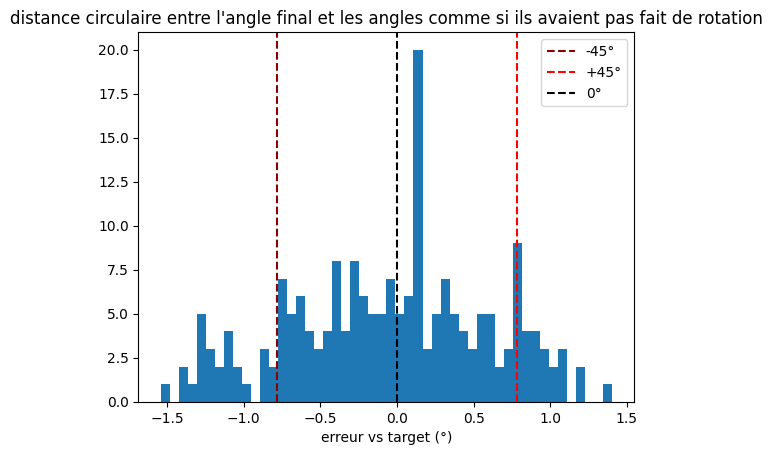

In [174]:
plt.hist(df_radian["error_wo_rotation"], bins=50)
plt.axvline(np.deg2rad(-45), color='darkred', linestyle='--', label="-45°") 
plt.axvline(np.deg2rad(45), color='red', linestyle='--', label="+45°") 
plt.axvline(np.deg2rad(0), color='black', linestyle='--', label="0°") 

plt.xlabel("erreur vs target (°)")
plt.title("distance circulaire entre l'angle final et les angles comme si ils avaient pas fait de rotation")
plt.legend()
plt.show()

### chatgpt : quelle rotation a été privilégiée

In [175]:
# # ================================
# # COMPARAISON DE MODÈLES DE STRATÉGIE
# # ================================

# # ---- helpers ----
# def mean_abs_error(err):
#     return np.nanmean(np.abs(err))


# def angle_pred_ignore_rotation(row, rot_to_ignore_rad):
#     """
#     Prédit l'angle attendu si on ignore une rotation spécifique
#     (rot_to_ignore_rad en radians, ex: ±np.deg2rad(45))
#     """
#     angles = []
#     for ang, rot in zip(row["presented_angles"], row["stimulus_rotations"]):
#         if not np.isclose(rot, rot_to_ignore_rad):
#             angles.append(ang + rot)
#     if len(angles) == 0:
#         return np.nan
#     return Angle_moyen_circulaire(np.array(angles))


# # ---- PRÉDICTIONS DES 4 MODÈLES ----

# # 1) Modèle correct (rotations bien appliquées)
# df_radian["theta_pred_correct"] = df_radian["expected_targets"]

# # 2) Modèle : rotations totalement ignorées
# df_radian["theta_pred_no_rot"] = df_radian["expected_angles_wo_rot"]

# # 3) Modèle : ignore -45°
# df_radian["theta_pred_ignore_minus45"] = df_radian.apply(
#     lambda row: angle_pred_ignore_rotation(row, -np.deg2rad(45)),
#     axis=1
# )

# # 4) Modèle : ignore +45°
# df_radian["theta_pred_ignore_plus45"] = df_radian.apply(
#     lambda row: angle_pred_ignore_rotation(row, np.deg2rad(45)),
#     axis=1
# )


# # ---- ERREURS CIRCULAIRES ----

# df_radian["err_correct"] = circular_error(
#     df_radian["final_angle"], df_radian["theta_pred_correct"]
# )

# df_radian["err_no_rot"] = circular_error(
#     df_radian["final_angle"], df_radian["theta_pred_no_rot"]
# )

# df_radian["err_ignore_minus45"] = circular_error(
#     df_radian["final_angle"], df_radian["theta_pred_ignore_minus45"]
# )

# df_radian["err_ignore_plus45"] = circular_error(
#     df_radian["final_angle"], df_radian["theta_pred_ignore_plus45"]
# )


# # ---- SCORE GLOBAL PAR MODÈLE ----

# scores = {
#     "Rotation correcte": mean_abs_error(df_radian["err_correct"]),
#     "Ignore toutes rotations": mean_abs_error(df_radian["err_no_rot"]),
#     "Ignore -45°": mean_abs_error(df_radian["err_ignore_minus45"]),
#     "Ignore +45°": mean_abs_error(df_radian["err_ignore_plus45"]),
# }

# print("\nErreur absolue circulaire moyenne par modèle :")
# for k, v in scores.items():
#     print(f"{k:25s} : {v:.4f} rad")


# # ---- MEILLEUR MODÈLE PAR ESSAI ----

# df_radian["best_model"] = df_radian[
#     ["err_correct", "err_no_rot", "err_ignore_minus45", "err_ignore_plus45"]
# ].abs().idxmin(axis=1)

# print("\nProportion d'essais expliqués par chaque modèle :")
# print(df_radian["best_model"].value_counts(normalize=True))


# # ---- VISUALISATION DES DISTRIBUTIONS D'ERREUR ----

# plt.figure(figsize=(10,6))
# plt.hist(df_radian["err_correct"], bins=60, alpha=0.5, label="Rotation correcte")
# plt.hist(df_radian["err_no_rot"], bins=60, alpha=0.5, label="Ignore rotations")
# plt.hist(df_radian["err_ignore_minus45"], bins=60, alpha=0.5, label="Ignore -45°")
# plt.hist(df_radian["err_ignore_plus45"], bins=60, alpha=0.5, label="Ignore +45°")
# plt.axvline(0, color="black", linestyle="--")
# plt.xlabel("Erreur circulaire (rad)")
# plt.ylabel("Nombre d'essais")
# plt.title("Comparaison des modèles de stratégie")
# plt.legend()
# plt.show()



❌ Ils n’ignorent pas globalement les rotations

❌ Ils n’ignorent pas symétriquement ±45°

✅ Ils montrent un biais sélectif contre la rotation −45°

🧠 Leur comportement est mixtes / stratégies multiples

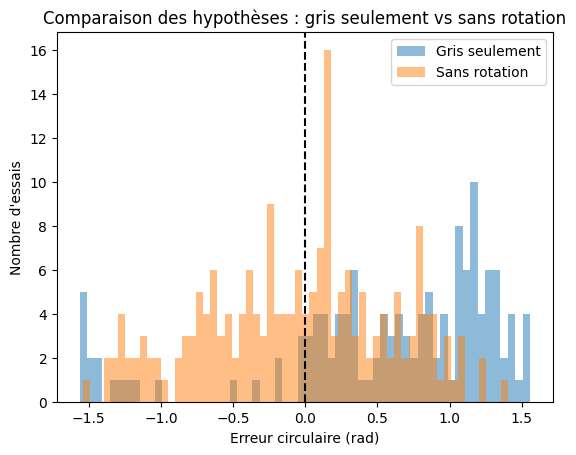

In [176]:
plt.hist(df_radian_error_wo_rotation["error_sola_gris"], 
         bins=60, alpha=0.5, label="Gris seulement")

plt.hist(df_radian["error_wo_rotation"], 
         bins=60, alpha=0.5, label="Sans rotation")

plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Erreur circulaire (rad)")
plt.ylabel("Nombre d'essais")
plt.title("Comparaison des hypothèses : gris seulement vs sans rotation")
plt.legend()
plt.show()

### rotation moyenne vs erreur

In [177]:
df_radian

,trial_rt,score,length of sequence,error_to_target,mean_rotation,final_angle,target,expected_targets,stimulus_rotations,presented_angles,expected_angles,rad_target_expected,dict_angle_to_rotation,angles_sans_rotation,expected_angles_wo_rot,error_wo_rotation
0,2305.0,6,3,0.212729,-15.000000,-0.430167,2.498241,2.498696,"[-0.7853981633974483, -0.7853981633974483, 0.7...","[3.252067471445352, 3.0106727580067814, 2.0187...","[2.466669308047903, 2.225274594609333, 2.80414...",-0.644843,"{3.252067471445352: -0.7853981633974483, 3.010...",[],-0.278611,-0.151556
1,1958.0,0,7,0.592163,-12.857143,-0.243618,2.315405,2.305811,"[0.7853981633974483, -0.7853981633974483, 0.78...","[1.7115227546124807, 3.371987102063714, 0.8661...","[2.496920918009929, 2.586588938666266, 1.65156...",-0.789767,"{1.7115227546124807: 0.7853981633974483, 3.371...",[2.6411345845106764],-0.001408,-0.242210
2,2380.0,6,5,0.289245,18.000000,2.554998,2.278856,2.265753,"[0.7853981633974483, 0.7853981633974483, 0.0, ...","[0.5934584351721087, 1.3713946414614882, 2.517...","[1.378856598569557, 2.156792804858936, 2.51714...",-0.808343,"{0.5934584351721087: 0.7853981633974483, 1.371...","[2.517148657266629, 2.326270515163634, 2.94969...",-0.503171,-0.083423
3,1969.0,0,3,-0.777387,-30.000000,0.921122,1.697874,1.698509,"[0.0, -0.7853981633974483, -0.7853981633974483]","[1.5153946746771307, 2.405401029975197, 2.7455...","[1.5153946746771307, 1.6200028665777488, 1.960...",-1.445733,"{1.5153946746771307: 0.0, 2.405401029975197: -...",[1.5153946746771307],-0.845640,-1.374830
4,1735.0,10,7,-0.033208,-12.857143,3.651889,0.544458,0.543504,"[-0.7853981633974483, -0.7853981633974483, 0.7...","[1.731041275770652, 1.5914395297000938, -0.393...","[0.9456431123732036, 0.8060413663026454, 0.392...",0.547585,"{1.731041275770652: -0.7853981633974483, 1.591...",[0.061922982618465],-1.248151,-1.383145
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,2426.0,10,1,-0.044334,-45.000000,-0.159352,3.026575,3.026575,[-0.7853981633974483],[3.8119733069593815],[3.0265751435619332],-0.115018,{3.8119733069593815: -0.7853981633974483},[],0.670381,-0.829732
196,2508.0,10,1,-0.003424,0.000000,0.274341,0.277765,0.277765,[0.0],[3.4193574930133703],[3.4193574930133703],0.277765,{3.4193574930133703: 0.0},[3.4193574930133703],0.277765,-0.003424
197,1822.0,10,5,-0.090173,-18.000000,-1.384799,1.843827,1.846966,"[-0.7853981633974483, -0.7853981633974483, 0.0...","[2.781073238426176, 2.6855314507426677, 1.5824...","[1.9956750750287275, 1.9001332873452197, 1.582...",-1.310359,"{2.781073238426176: -0.7853981633974483, 2.685...","[1.5824490091682564, 2.618553987170089, 1.1380...",-0.717326,-0.667474
198,1814.0,0,1,-1.559325,-45.000000,-1.035841,0.523484,0.523484,[-0.7853981633974483],[1.3088821824978711],[0.5234840191004229],0.523484,{1.3088821824978711: -0.7853981633974483},[],1.308882,0.796869


In [187]:
df_radian["mean_rotation"] = ((df_radian["stimulus_rotations"].apply(np.sum)+np.pi/2)%np.pi)-np.pi/2

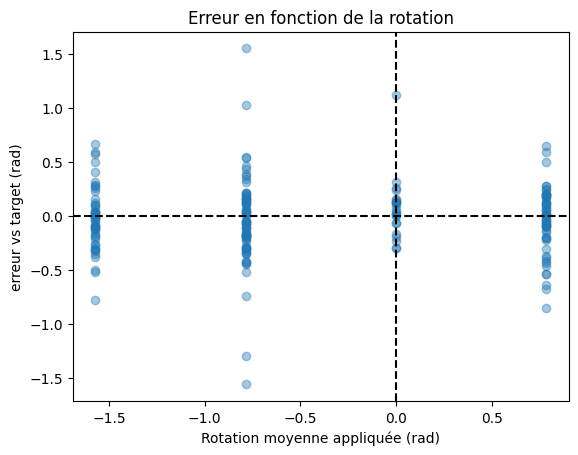

In [188]:
plt.scatter(df_radian["mean_rotation"], df_radian["error_to_target"], alpha=0.4)
plt.axhline(0, color="black", linestyle="--")   
plt.axvline(0, color="black", linestyle="--")   
plt.xlabel("Rotation moyenne appliquée (rad)")
plt.ylabel("erreur vs target (rad)")
plt.title("Erreur en fonction de la rotation")
plt.show()

## Reaction time et confiance

### RT vs erreur

erreur entre l'angle tiré et la target en fonction du temps de réaction 

*on observe que l'erreur semble être corrélée au temps de réaction, ce qui suggère que les participants font moins d'erreur quand ils répondent plus rapidement*

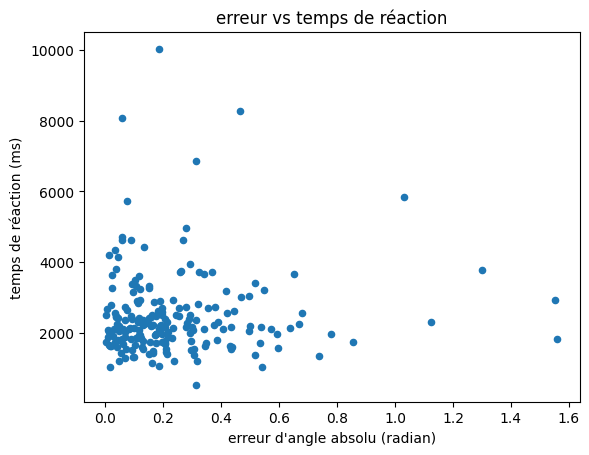

In [180]:
plt.scatter(np.abs(df_radian["error_to_target"]), df_radian["trial_rt"], s=20)
plt.xlabel("erreur d'angle absolu (radian)")
plt.ylabel("temps de réaction (ms)")
plt.title("erreur vs temps de réaction")
plt.show()

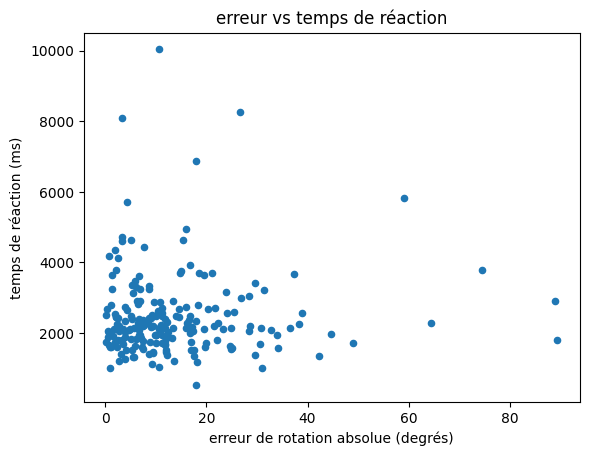

In [181]:
plt.scatter(np.abs(df_filtered["error_to_target"]), df_filtered["trial_rt"], s=20)
plt.xlabel("erreur de rotation absolue (degrés)")
plt.ylabel("temps de réaction (ms)")
plt.title("erreur vs temps de réaction")
plt.show()

erreur vs le temps

In [182]:
df_radian

,trial_rt,score,length of sequence,error_to_target,mean_rotation,final_angle,target,expected_targets,stimulus_rotations,presented_angles,expected_angles,rad_target_expected,dict_angle_to_rotation,angles_sans_rotation,expected_angles_wo_rot,error_wo_rotation
0,2305.0,6,3,0.212729,-0.261799,-0.430167,2.498241,2.498696,"[-0.7853981633974483, -0.7853981633974483, 0.7...","[3.252067471445352, 3.0106727580067814, 2.0187...","[2.466669308047903, 2.225274594609333, 2.80414...",-0.644843,"{3.252067471445352: -0.7853981633974483, 3.010...",[],-0.278611,-0.151556
1,1958.0,0,7,0.592163,-0.224399,-0.243618,2.315405,2.305811,"[0.7853981633974483, -0.7853981633974483, 0.78...","[1.7115227546124807, 3.371987102063714, 0.8661...","[2.496920918009929, 2.586588938666266, 1.65156...",-0.789767,"{1.7115227546124807: 0.7853981633974483, 3.371...",[2.6411345845106764],-0.001408,-0.242210
2,2380.0,6,5,0.289245,0.314159,2.554998,2.278856,2.265753,"[0.7853981633974483, 0.7853981633974483, 0.0, ...","[0.5934584351721087, 1.3713946414614882, 2.517...","[1.378856598569557, 2.156792804858936, 2.51714...",-0.808343,"{0.5934584351721087: 0.7853981633974483, 1.371...","[2.517148657266629, 2.326270515163634, 2.94969...",-0.503171,-0.083423
3,1969.0,0,3,-0.777387,-0.523599,0.921122,1.697874,1.698509,"[0.0, -0.7853981633974483, -0.7853981633974483]","[1.5153946746771307, 2.405401029975197, 2.7455...","[1.5153946746771307, 1.6200028665777488, 1.960...",-1.445733,"{1.5153946746771307: 0.0, 2.405401029975197: -...",[1.5153946746771307],-0.845640,-1.374830
4,1735.0,10,7,-0.033208,-0.224399,3.651889,0.544458,0.543504,"[-0.7853981633974483, -0.7853981633974483, 0.7...","[1.731041275770652, 1.5914395297000938, -0.393...","[0.9456431123732036, 0.8060413663026454, 0.392...",0.547585,"{1.731041275770652: -0.7853981633974483, 1.591...",[0.061922982618465],-1.248151,-1.383145
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,2426.0,10,1,-0.044334,-0.785398,-0.159352,3.026575,3.026575,[-0.7853981633974483],[3.8119733069593815],[3.0265751435619332],-0.115018,{3.8119733069593815: -0.7853981633974483},[],0.670381,-0.829732
196,2508.0,10,1,-0.003424,0.000000,0.274341,0.277765,0.277765,[0.0],[3.4193574930133703],[3.4193574930133703],0.277765,{3.4193574930133703: 0.0},[3.4193574930133703],0.277765,-0.003424
197,1822.0,10,5,-0.090173,-0.314159,-1.384799,1.843827,1.846966,"[-0.7853981633974483, -0.7853981633974483, 0.0...","[2.781073238426176, 2.6855314507426677, 1.5824...","[1.9956750750287275, 1.9001332873452197, 1.582...",-1.310359,"{2.781073238426176: -0.7853981633974483, 2.685...","[1.5824490091682564, 2.618553987170089, 1.1380...",-0.717326,-0.667474
198,1814.0,0,1,-1.559325,-0.785398,-1.035841,0.523484,0.523484,[-0.7853981633974483],[1.3088821824978711],[0.5234840191004229],0.523484,{1.3088821824978711: -0.7853981633974483},[],1.308882,0.796869


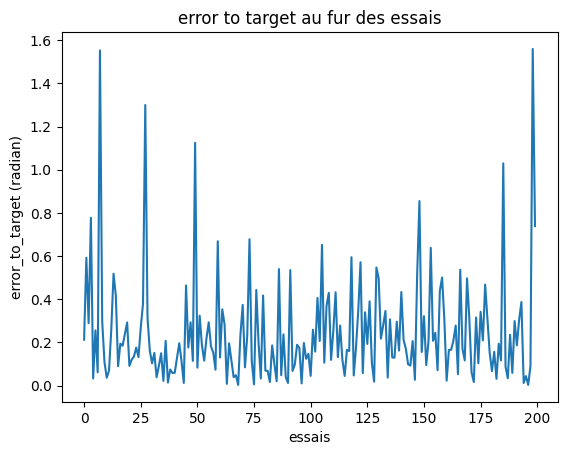

In [183]:
plt.plot(np.abs(df_radian["error_to_target"]))
plt.xlabel("essais")
plt.ylabel("error_to_target (radian)")
plt.title("error to target au fur des essais")
plt.show()

RT vs seq length

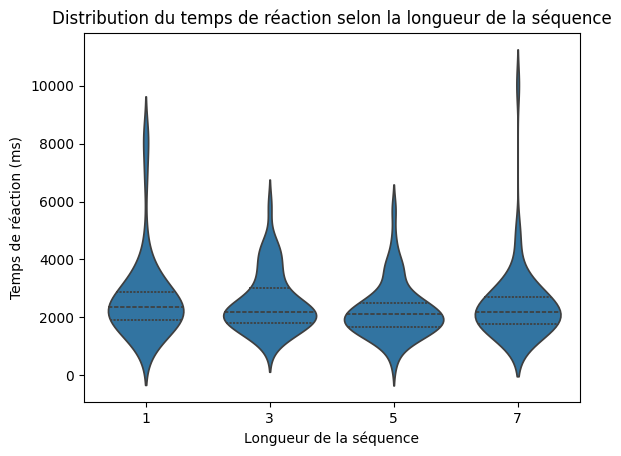

In [184]:
import seaborn as sns

plt.figure()

sns.violinplot(x="length of sequence", y="trial_rt", data=df_radian, inner="quartile")

plt.xlabel("Longueur de la séquence")
plt.ylabel("Temps de réaction (ms)")
plt.title("Distribution du temps de réaction selon la longueur de la séquence")

plt.show()

### RT vs la confiance 

### RT vs score

### RT threshold